# Coin Flip 2 

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService

In [2]:
# At some point we will make this a utlity function in the qiskit-ibm-runtime package itself
def get_api_key(db_path, table_name, column_name, condition):
    import sqlite3
    """
    Retrieves an API key from an SQLite database.
    :param db_path: Path to the SQLite database file.
    :param table_name: Name of the table containing the API key.
    :param column_name: Column name where the API key is stored.
    :param condition: SQL condition to fetch the correct API key (e.g., "id=1").
    :return: API key as a string or None if not found.
    """
    try:
        conn = sqlite3.connect(db_path)
        cursor = conn.cursor()
        
        query = f"SELECT {column_name} FROM {table_name} WHERE {condition}"
        cursor.execute(query)
        result = cursor.fetchone()
        
        conn.close()
        
        return result[0] if result else None
    except sqlite3.Error as e:
        print(f"Database error: {e}")
        return None

In [12]:
# Get IBM Quantum API key 
# we need to simplify this 
db_path = "C:\\Users\\patri\\OneDrive\\Projects\\admin\\api_store.db" 
table = "api_keys"
column_id = "key" 
condition = "service='ibm_quantum'"
api_key = get_api_key(db_path, table, column_id, condition)
if api_key is None:
    raise ValueError("API key not found in the database.")

In [3]:
# import the packages installed to your environment
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

import numpy as np

## Create the Circuit 

In [4]:
# create an object that is of type QuantumCircuit with two qubits.
circuit = QuantumCircuit(2)

# We will add gates ("operations") to this object below, much like how you may add a series of machines to assembly lines.
circuit.h(0) # add a Hadamard gate to the zeroth qubit (labelling the qubits starts at 0 and goes to 1, 2, ...)
circuit.cx(0, 1) # add a CNOT controlled by the zeroth qubit and applied to the first qubit

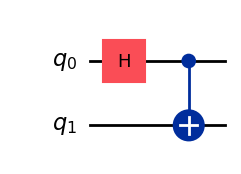

In [5]:
# visualize the circuit below
circuit.draw('mpl')

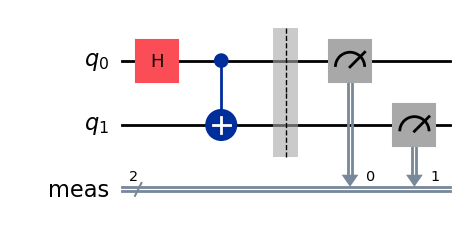

In [6]:
# indicate that you want your quantum circuit to measure all qubits at the end
circuit.measure_all()
# illustrate the circuit with the measurements
circuit.draw('mpl')

In [7]:
# create an instance of the Qiskit StatevectorSampler
sampler = StatevectorSampler()

# run the job on the StatevectorSampler, passing in the circuit. There will be 256 samples taken.
job_sampler = sampler.run([(circuit)], shots=256)

In [8]:
# get the results from the sampler
result_sampler = job_sampler.result()

# to get a dictionary of data mapping {state : number of samples}, we use get_counts()
counts = result_sampler[0].data.meas.get_counts()
print(counts)

{'11': 125, '00': 131}


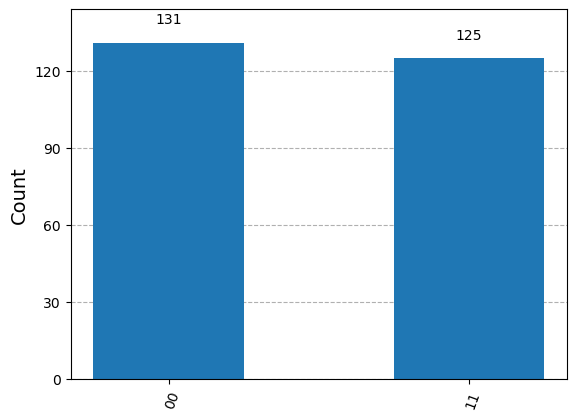

In [9]:
# we can plot these counts to show the distribution of results
plot_histogram(counts)

# Transpile the circuit 

In [10]:
# redefine the circuit
# create an object that is of type QuantumCircuit with two qubits.
circuit = QuantumCircuit(2)

# apply quantum gates to construct the Bell State
circuit.h(0)
circuit.cx(0, 1)

## Find Backend

In [13]:
service = QiskitRuntimeService(channel="ibm_quantum", token=api_key)
service.backends()

[<IBMBackend('ibm_brisbane')>,
 <IBMBackend('ibm_kyiv')>,
 <IBMBackend('ibm_sherbrooke')>]

In [14]:

# Make sure that you have access to the backend 
# make sure you capture the backend as an object to use in the next steps.
# Note: The backend name may vary based on availability and your access level.
backend = service.backend('ibm_kyiv') # List available backends for the IBM Kyiv service
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)

In [15]:
transpiled_circuit = pass_manager.run(circuit)

## Step 3 - Execute on Backend

In [18]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Initialize the service and retrieve the backend
service = QiskitRuntimeService()
backend = service.backend("ibm_kyiv")  # Replace "ibm_kyiv" with your desired backend

# Create the Estimator with the backend
estimator = Estimator(backend)

In [40]:
job = estimator.run([(circuit, observables)])  # Run the job with 256 shots for each observable
# Get the result from the job
job_id = job.job_id()

IBMInputValueError: 'The instruction h on qubits (0,) is not supported by the target system. Circuits that do not match the target hardware definition are no longer supported after March 4, 2024. See the transpilation documentation (https://docs.quantum.ibm.com/guides/transpile) for instructions to transform circuits and the primitive examples (https://docs.quantum.ibm.com/guides/primitives-examples) to see this coupled with operator transformations.'